# Seq2Seq Recipe Generation: LSTM + Pointer-Generator Network

Pointer-generator with coverage: copies ingredient tokens directly when needed.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aryabhardwaj23/AI-PROJECTS/blob/main/Natural%20language%20processing%28NLP%29/recipe-generation-seq2seq/seq2seq_pointer_generator.ipynb)

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch import optim
import numpy as np
import random
import re
import unicodedata
from torch.utils.data import Dataset, DataLoader
import csv
from collections import Counter
import ast
import matplotlib.ticker as ticker
import time
import math
import matplotlib.pyplot as plt
import pandas as pd, ast, re
import nltk
from torch.nn.utils.rnn import pad_sequence

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [3]:
!wget http://nlp.stanford.edu/data/glove.6B.zip
!unzip -o glove.6B.zip


--2025-05-23 08:53:44--  http://nlp.stanford.edu/data/glove.6B.zip
Resolving nlp.stanford.edu (nlp.stanford.edu)... 171.64.67.140
Connecting to nlp.stanford.edu (nlp.stanford.edu)|171.64.67.140|:80... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://nlp.stanford.edu/data/glove.6B.zip [following]
--2025-05-23 08:53:44--  https://nlp.stanford.edu/data/glove.6B.zip
Connecting to nlp.stanford.edu (nlp.stanford.edu)|171.64.67.140|:443... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://downloads.cs.stanford.edu/nlp/data/glove.6B.zip [following]
--2025-05-23 08:53:44--  https://downloads.cs.stanford.edu/nlp/data/glove.6B.zip
Resolving downloads.cs.stanford.edu (downloads.cs.stanford.edu)... 171.64.64.22
Connecting to downloads.cs.stanford.edu (downloads.cs.stanford.edu)|171.64.64.22|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 862182613 (822M) [application/zip]
Saving to: ‘glove.6B.zip’

glov

In [4]:
def parse_list_column(col):
    try:
        return ast.literal_eval(col) if isinstance(col, str) and col.startswith('[') else []
    except Exception:
        return []

def preprocess_ingredients(ings):
    tokens = []
    for ing in ings:
        tokens.extend(re.findall(r"\b\w+\b", ing.lower()))
    return tokens


def preprocess_recipe(recipe):
    sentences = []
    for step in recipe:
        sentences.extend([sent.strip().lower() for sent in re.split(r'[.!?]', step) if sent.strip()])
    return sentences

def build_vocab(sequences):
    counter = Counter(w for seq in sequences for w in seq)
    vocab = {'PAD': 0, 'SOS': 1, 'EOS': 2, 'UNK': 3}
    idx = 4
    for word, _ in counter.most_common():
        vocab[word] = idx
        idx += 1
    return vocab


def indexes_from_sentence(vocab, sentence):
    return [vocab['SOS']] + [vocab.get(word, vocab['UNK']) for word in sentence] + [vocab['EOS']]

def tensor_from_sentence(vocab, sentence, max_len=None):
    indexes = indexes_from_sentence(vocab, sentence)
    return torch.tensor(indexes, dtype=torch.long)

def tensors_from_pair(pair, ingredient_vocab, recipe_vocab):
    input_tensor = tensor_from_sentence(ingredient_vocab, pair[0])
    target_tensor = tensor_from_sentence(recipe_vocab, pair[1])
    return (input_tensor, target_tensor)

In [5]:
class RecipeDataset(Dataset):
    def __init__(self, pairs, ingredient_vocab, recipe_vocab, max_len):
        self.pairs = pairs
        self.ingredient_vocab = ingredient_vocab
        self.recipe_vocab = recipe_vocab
        self.max_len = max_len
    def __len__(self):
        return len(self.pairs)
    def __getitem__(self, idx):
        ing_tokens = self.pairs[idx][0]
        rec_tokens = self.pairs[idx][1]
        inp = tensor_from_sentence(self.ingredient_vocab, ing_tokens, self.max_len)
        out = tensor_from_sentence(self.recipe_vocab, rec_tokens, self.max_len)
        return inp, out

In [6]:
train_df = pd.read_csv("train.csv", nrows=90000)
train_df["Ingredients"] = train_df["Ingredients"].apply(ast.literal_eval)
train_df["Recipe"] = train_df["Recipe"].apply(ast.literal_eval)
# Apply preprocessing
train_df["ingredient_tokens"] = train_df["Ingredients"].apply(preprocess_ingredients)
train_df["recipe_tokens"] = train_df["Recipe"].apply(preprocess_recipe)

# Combine into (input, target) pairs
train_pairs = list(zip(train_df["ingredient_tokens"], train_df["recipe_tokens"]))
ingredient_vocab = build_vocab(train_df["ingredient_tokens"].tolist())
recipe_vocab = build_vocab(train_df["recipe_tokens"].tolist())


# Load and preprocess test.csv
test_df = pd.read_csv("test.csv")
test_df["Ingredients"] = test_df["Ingredients"].apply(ast.literal_eval)
test_df["Recipe"] = test_df["Recipe"].apply(ast.literal_eval)
test_df["ingredient_tokens"] = test_df["Ingredients"].apply(preprocess_ingredients)
test_df["recipe_tokens"] = test_df["Recipe"].apply(preprocess_recipe)

# Create test pairs
test_pairs = list(zip(test_df["ingredient_tokens"], test_df["recipe_tokens"]))

# Convert to tensor pairs
test_tensor_pairs = [tensors_from_pair(pair, ingredient_vocab, recipe_vocab) for pair in test_pairs]


In [7]:
print("Ingredient vocab size:", len(ingredient_vocab))
print("Recipe vocab size:", len(recipe_vocab))

Ingredient vocab size: 7252
Recipe vocab size: 346283


In [22]:
def load_glove_embeddings(glove_file_path, embedding_dim):
    embeddings_index = {}
    with open(glove_file_path, encoding='utf8') as f:
        for line in f:
            values = line.split()
            word = values[0]
            coefs = np.asarray(values[1:], dtype='float32')
            embeddings_index[word] = coefs
    return embeddings_index

embedding_dim = 100
glove_path = "glove.6B.100d.txt"
glove_embeddings = load_glove_embeddings(glove_path, embedding_dim)

def build_embedding_matrix(vocab, embeddings_index, embedding_dim):
    matrix = np.random.normal(scale=0.6, size=(len(vocab), embedding_dim))
    for word, idx in vocab.items():
        if word in embeddings_index:
            matrix[idx] = embeddings_index[word]
    return torch.tensor(matrix, dtype=torch.float32)

ingredient_embedding_matrix = build_embedding_matrix(ingredient_vocab, glove_embeddings, embedding_dim)

In [24]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class LSTMEncoder(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers=1, dropout=0.1):
        super().__init__()
        self.embedding = nn.Embedding(input_size, hidden_size, padding_idx=0)
        self.lstm = nn.LSTM(hidden_size, hidden_size, num_layers=num_layers,
                            dropout=dropout if num_layers > 1 else 0, batch_first=True)
    def forward(self, input_seq):
        embedded = self.embedding(input_seq)
        outputs, (hidden, cell) = self.lstm(embedded)
        return outputs, hidden, cell

class PointerGeneratorCoverageDecoder(nn.Module):
    def __init__(self, hidden_size, output_size, embedding_dim, num_layers=1, dropout=0.1):
        super().__init__()
        self.embedding = nn.Embedding(output_size, embedding_dim, padding_idx=0)
        self.lstm = nn.LSTM(embedding_dim, hidden_size, num_layers=num_layers,
                            dropout=dropout if num_layers > 1 else 0, batch_first=True)
        self.attn = nn.Linear(hidden_size * 2 + 1, 1)  # +1 for coverage
        self.out = nn.Linear(hidden_size, output_size)
        self.p_gen_linear = nn.Linear(hidden_size * 2 + embedding_dim, 1)

    def forward(self, input_step, hidden, cell, encoder_outputs, src_seq, coverage):
        # input_step: (batch, 1)
        embedded = self.embedding(input_step)  # (batch, 1, emb)
        lstm_out, (hidden, cell) = self.lstm(embedded, (hidden, cell))
        dec_out = lstm_out.squeeze(1)

        src_len = encoder_outputs.size(1)
        batch_size = encoder_outputs.size(0)

        dec_out_exp = dec_out.unsqueeze(1).expand(-1, src_len, -1)
        coverage_unsq = coverage.unsqueeze(2)

        attn_input = torch.cat([encoder_outputs, dec_out_exp, coverage_unsq], dim=2)
        attn_scores = self.attn(attn_input).squeeze(-1)
        attn_weights = torch.softmax(attn_scores, dim=1)

        # context vector
        context = torch.bmm(attn_weights.unsqueeze(1), encoder_outputs).squeeze(1)

        # Pointer-generator
        p_gen_input = torch.cat([dec_out, context, embedded.squeeze(1)], dim=1)
        p_gen = torch.sigmoid(self.p_gen_linear(p_gen_input))

        vocab_dist = torch.softmax(self.out(dec_out), dim=-1)
        final_dist = p_gen * vocab_dist

        # Copy mechanism (vectorized)
        attn_dist = (1 - p_gen) * attn_weights  # (batch, src_len)
        extended_final_dist = final_dist.clone()
        # Vectorized scatter_add for copy mechanism
        extended_final_dist = extended_final_dist.scatter_add(
            1, src_seq, attn_dist
        )

        new_coverage = coverage + attn_weights

        return extended_final_dist, hidden, cell, attn_weights, new_coverage, p_gen


In [30]:
def collate_fn(batch):
    inputs, targets = zip(*batch)
    inputs_padded = pad_sequence(inputs, batch_first=True, padding_value=0)
    targets_padded = pad_sequence(targets, batch_first=True, padding_value=0)
    # For copy mechanism, keep a version of the input with correct indices
    return inputs_padded, targets_padded, inputs_padded

max_len = 100
train_dataset = RecipeDataset(train_pairs, ingredient_vocab, recipe_vocab, max_len=max_len)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, collate_fn=collate_fn)


In [31]:
def train_batch(inputs, targets, src_seqs, encoder, decoder, enc_opt, dec_opt, criterion, lambda_cov=0.5, teacher_forcing_ratio=None):
    batch_size, tgt_len = targets.size()
    encoder_outputs, encoder_hidden, encoder_cell = encoder(inputs)

    decoder_input = torch.full((batch_size, 1), recipe_vocab['SOS'], dtype=torch.long, device=device)
    decoder_hidden = encoder_hidden
    decoder_cell = encoder_cell

    coverage = torch.zeros(batch_size, inputs.size(1), device=device)
    loss = 0
    cov_loss = 0

    for t in range(tgt_len):
        prev_coverage = coverage.clone()
        final_dist, decoder_hidden, decoder_cell, attn_weights, coverage, p_gen = decoder(decoder_input, decoder_hidden, decoder_cell, encoder_outputs, src_seqs, coverage)
        nll = criterion(torch.log(final_dist + 1e-12), targets[:, t])
        cov_loss += torch.sum(torch.min(attn_weights, prev_coverage))
        loss += nll

        use_teacher_forcing = random.random() < teacher_forcing_ratio
        top1 = final_dist.argmax(-1, keepdim=True)
        decoder_input = targets[:, t].unsqueeze(1) if use_teacher_forcing else top1

    # Combine losses
    loss = loss / tgt_len + lambda_cov * cov_loss / tgt_len

    loss.backward()
    torch.nn.utils.clip_grad_norm_(encoder.parameters(), max_norm=5)
    torch.nn.utils.clip_grad_norm_(decoder.parameters(), max_norm=5)
    enc_opt.step()
    dec_opt.step()

    return loss.item()


In [32]:
def get_teacher_forcing_ratio(step):
    return 0.1

In [33]:
def showPlot(points):
    plt.figure(figsize=(8, 5))
    plt.plot(points)
    plt.title("Training Loss")
    plt.xlabel("Iterations (per plot_every)")
    plt.ylabel("Loss")
    plt.grid(True)
    ax = plt.gca()
    loc = ticker.MultipleLocator(base=0.2)
    ax.yaxis.set_major_locator(loc)
    plt.show()


In [34]:
def train_epochs(train_loader, encoder, decoder, recipe_vocab, n_epochs=None):
    encoder.train()
    decoder.train()
    all_losses = []
    enc_opt = torch.optim.Adam(encoder.parameters(), lr=0.001)
    dec_opt = torch.optim.Adam(decoder.parameters(), lr=0.001)
    criterion = nn.NLLLoss(ignore_index=0)

    step = 0
    for epoch in range(1, n_epochs + 1):
        epoch_loss = 0
        for batch_idx, (inputs, targets, src_seqs) in enumerate(train_loader):
            inputs, targets, src_seqs = inputs.to(device), targets.to(device), src_seqs.to(device)
            step += 1
            tf_ratio = get_teacher_forcing_ratio(step)
            loss = train_batch(inputs, targets, src_seqs, encoder, decoder, enc_opt, dec_opt, criterion, teacher_forcing_ratio=tf_ratio)
            epoch_loss += loss

        avg_loss = epoch_loss / len(train_loader)
        all_losses.append(avg_loss)
        print(f"Epoch {epoch} | TF ratio: {tf_ratio:.2f} | Loss: {avg_loss:.4f}")
    showPlot(all_losses)
    return all_losses


Epoch 1 | TF ratio: 0.10 | Loss: 16.5595
Epoch 2 | TF ratio: 0.10 | Loss: 16.0546
Epoch 3 | TF ratio: 0.10 | Loss: 15.7827
Epoch 4 | TF ratio: 0.10 | Loss: 15.4641
Epoch 5 | TF ratio: 0.10 | Loss: 15.1647


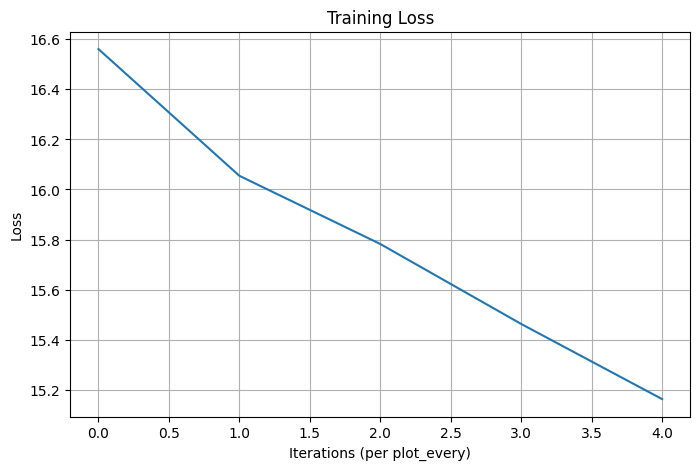

[16.559524570549858,
 16.054569552781846,
 15.782717135450575,
 15.464066983710396,
 15.164672564358181]

In [35]:
num_layers = 2
encoder = LSTMEncoder(len(ingredient_vocab), hidden_size=256).to(device)
embedding_dim = 100
decoder = PointerGeneratorCoverageDecoder(hidden_size=256, output_size=len(recipe_vocab), embedding_dim=embedding_dim).to(device)

train_epochs(train_loader, encoder, decoder, recipe_vocab, n_epochs=5)


In [40]:
def evaluate_model_loss(encoder, decoder, tensor_pairs, criterion, max_length=100):
    total_loss = 0
    with torch.no_grad():
        for input_tensor, target_tensor in tensor_pairs:
            input_tensor = input_tensor.unsqueeze(0).to(device)
            target_tensor = target_tensor.to(device)

            encoder_hidden, encoder_cell = encoder(input_tensor)
            decoder_input = torch.tensor([[recipe_vocab['SOS']]], device=device)
            decoder_hidden = encoder_hidden
            decoder_cell = encoder_cell

            loss = 0
            for di in range(target_tensor.size(0)):
                decoder_output, decoder_hidden, decoder_cell = decoder(decoder_input, decoder_hidden, decoder_cell)
                loss += criterion(decoder_output, target_tensor[di].unsqueeze(0))
                topv, topi = decoder_output.topk(1)
                decoder_input = topi.detach().unsqueeze(1)

                if topi.item() == recipe_vocab['EOS']:
                    break

            total_loss += loss.item() / target_tensor.size(0)

    return total_loss / len(tensor_pairs)


In [43]:
def generate_text(encoder, decoder, input_tensor, recipe_vocab, max_length=100):
    input_tensor = input_tensor.unsqueeze(0).to(device)
    encoder_outputs, encoder_hidden, encoder_cell = encoder(input_tensor)

    decoder_input = torch.tensor([[recipe_vocab['SOS']]], device=device)
    decoder_hidden = encoder_hidden
    decoder_cell = encoder_cell
    coverage = torch.zeros(encoder_outputs.size(0), encoder_outputs.size(1), device=device)
    src_seq = input_tensor  # (batch, seq_len) -- needed for pointer/copy

    generated_tokens = []

    for _ in range(max_length):
        decoder_output, decoder_hidden, decoder_cell, attn_weights, coverage, p_gen = decoder(
            decoder_input, decoder_hidden, decoder_cell, encoder_outputs, src_seq, coverage
        )
        topi = decoder_output.argmax(-1)
        next_token = topi.item()
        if next_token == recipe_vocab['EOS']:
            break
        word = recipe_vocab_inv.get(next_token, "<UNK>")
        generated_tokens.append(word)
        decoder_input = topi.unsqueeze(0)
    return generated_tokens


In [108]:
# Reverse vocab
recipe_vocab_inv = {v: k for k, v in recipe_vocab.items()}

# Print 5 sample outputs
random_indices = random.sample(range(len(test_pairs)), 5)
for i, idx in enumerate(random_indices):
    ingredients_tokens, ground_truth_tokens = test_pairs[idx]
    input_tensor = tensor_from_sentence(ingredient_vocab, ingredients_tokens, max_len)
    generated_tokens = generate_text(encoder, decoder, input_tensor, recipe_vocab, max_length=max_len)

    print(f"--- Example {i+1} (Test Index: {idx}) ---")
    print("Ingredients:", " ".join(ingredients_tokens))
    print("Ground Truth Recipe:", " ".join(ground_truth_tokens))
    print("Generated Recipe:", " ".join(generated_tokens))
    print()

--- Example 1 (Test Index: 660) ---
Ingredients: 4 4 oz boneless chicken breast halves skinned dijon pepper to taste chicken soup mix to taste vegetable cooking spray 2 tsp vegetable oil 1 2 c orange juice 2 tbsp brown sugar 2 tbsp catsup 1 1 2 tbsp parisienne mustard 1 tbsp white wine vinegar 2 tsp cornstarch 1 2 tsp chicken soup mix 1 8 tsp dijon pepper 1 11 oz can mandarin oranges drained
Ground Truth Recipe: sprinkle chicken breasts generously with dijon pepper and chicken soup mix coat a large skillet with cooking spray add vegetable oil place skillet over medium-high heat until hot add chicken to skillet and cook 2 to 3 minutes on each side or until lightly browned
Generated Recipe: SOS mix all ingredients together

--- Example 2 (Test Index: 580) ---
Ingredients: 1 gal cucumbers sliced 8 small onions sliced 2 green sweet peppers sliced 1 2 c salt 5 c sugar 5 c vinegar 1 1 2 tsp turmeric 1 tsp celery seed 1 1 2 tsp ground cloves 2 tbsp mustard seed
Ground Truth Recipe: combine cu

In [109]:
!pip install nltk bert-score --quiet
!pip install bert-score
import nltk
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from nltk.translate.meteor_score import meteor_score
from bert_score import score
import torch
import pandas as pd
import ast, re
from tqdm import tqdm

nltk.download('punkt')
nltk.download('wordnet')
nltk.download('omw-1.4')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 130.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 102.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 63.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 44.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 19.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 105.1 MB/s eta 0:00:00


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [119]:
def evaluate_generated_outputs(test_tensor_pairs, encoder, decoder, recipe_vocab, max_len=100, device='cpu'):
    bleu_scores = []
    meteor_scores = []
    references = []
    candidates = []

    encoder.eval()
    decoder.eval()

    for input_tensor, target_tensor in test_tensor_pairs[:200]:
        input_tensor = input_tensor.unsqueeze(0).to(device)
        target_tensor = target_tensor.to(device)

        with torch.no_grad():
            encoder_outputs, encoder_hidden, encoder_cell = encoder(input_tensor)
            decoder_input = torch.tensor([[recipe_vocab['SOS']]], device=device)
            decoder_hidden = encoder_hidden
            decoder_cell = encoder_cell
            src_seq = input_tensor  # (batch, src_len)
            coverage = torch.zeros(encoder_outputs.size(0), encoder_outputs.size(1), device=device)
            generated_tokens = []

            for _ in range(max_len):
                decoder_output, decoder_hidden, decoder_cell, attn_weights, coverage, p_gen = decoder(
                    decoder_input, decoder_hidden, decoder_cell, encoder_outputs, src_seq, coverage
                )
                topi = decoder_output.argmax(-1)
                token_id = topi.squeeze().item()
                if token_id == recipe_vocab['EOS']:
                    break
                word = next((k for k, v in recipe_vocab.items() if v == token_id), "<UNK>")
                generated_tokens.append(word)
                decoder_input = topi.unsqueeze(0)

        reference = [next((k for k, v in recipe_vocab.items() if v == idx.item()), "<UNK>")
                     for idx in target_tensor[1:-1]]
        candidate = generated_tokens

        if reference and candidate:
            smoothie = SmoothingFunction().method4
            bleu = sentence_bleu([reference], candidate, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=smoothie)
            meteor = meteor_score([reference], candidate)
            bleu_scores.append(bleu)
            meteor_scores.append(meteor)
            references.append(' '.join(reference))
            candidates.append(' '.join(candidate))

    if candidates and references:
        P, R, F1 = score(candidates, references, lang='en', verbose=False)
        bertscore_f1 = F1.mean().item()
    else:
        bertscore_f1 = 0.0

    print("\n=== Average Scores on Test Set ===")
    print(f"BLEU-4: {sum(bleu_scores)/len(bleu_scores):.4f}" if bleu_scores else "BLEU-4: No valid scores")
    print(f"METEOR: {sum(meteor_scores)/len(meteor_scores):.4f}" if meteor_scores else "METEOR: No valid scores")
    print(f"BERTScore (F1): {bertscore_f1:.4f}")

    encoder.train()
    decoder.train()

evaluate_generated_outputs(test_tensor_pairs, encoder, decoder, recipe_vocab, max_len=100, device=device)

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


model.safetensors:   0%|          | 0.00/1.42G [00:00<?, ?B/s]

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



=== Average Scores on Test Set ===
BLEU-4: 0.0004
METEOR: 0.0028
BERTScore (F1): 0.8046


In [120]:
import pandas as pd
import ast, re, torch
from tqdm import tqdm

def clean_and_tokenize_ingredients(ingredient_text):
    try:
        ingredients = ast.literal_eval(ingredient_text) if isinstance(ingredient_text, str) else []
    except:
        ingredients = []
    tokens = []
    for ing in ingredients:
        tokens.extend(re.findall(r'\b\w+\b', ing.lower()))
    return tokens

def generate_recipe(ingredient_tokens, encoder, decoder, ingredient_vocab, recipe_vocab, max_len=100):
    input_indexes = [ingredient_vocab.get(w, ingredient_vocab['UNK']) for w in ingredient_tokens]
    input_tensor = torch.tensor([ingredient_vocab['SOS']] + input_indexes + [ingredient_vocab['EOS']],
                                dtype=torch.long).unsqueeze(0).to(device)

    encoder_outputs, encoder_hidden, encoder_cell = encoder(input_tensor)

    decoder_input = torch.tensor([[recipe_vocab['SOS']]], device=input_tensor.device)
    decoder_hidden = encoder_hidden
    decoder_cell = encoder_cell
    src_seq = input_tensor  # Needed for pointer/copy mechanism
    coverage = torch.zeros(encoder_outputs.size(0), encoder_outputs.size(1), device=input_tensor.device)
    output_words = []

    for _ in range(max_len):
        decoder_output, decoder_hidden, decoder_cell, attn_weights, coverage, p_gen = decoder(
            decoder_input, decoder_hidden, decoder_cell, encoder_outputs, src_seq, coverage
        )
        topi = decoder_output.argmax(-1)
        next_token = topi.item()
        if next_token == recipe_vocab['EOS']:
            break
        word = next((k for k, v in recipe_vocab.items() if v == next_token), "<UNK>")
        output_words.append(word)
        decoder_input = topi.unsqueeze(0)  # keep batch dimension
    return ' '.join(output_words)



df = pd.read_csv("generated_filled.csv")

baseline1_outputs = []
for ing_text in tqdm(df["Ingredients"], desc="Recipe - Spicy Ext 2"):
    tokens = clean_and_tokenize_ingredients(ing_text)
    gen1 = generate_recipe(tokens, encoder, decoder, ingredient_vocab, recipe_vocab)
    baseline1_outputs.append(gen1)

df["Recipe - Spicy Ext 2"] = baseline1_outputs

# Save updated file as CSV
df.to_csv("generated_filled.csv", index=False, encoding='utf-8-sig')
print("Updated predictions written to: generated_filled.csv")


Recipe - Spicy Ext 2: 100%|██████████| 1081/1081 [00:04<00:00, 219.35it/s]


Updated predictions written to: generated_filled.csv


In [121]:
df = pd.read_csv("generated_filled.csv")
print(df[["Ingredients", "Recipe - Spicy Ext 2"]].head(10))

                                         Ingredients  \
0  ["1 (8 oz.) pkg. cream cheese", "1 small jar M...   
1  ["1 lb. ground beef", "1/2 c. onions, cut up (...   
2  ["1 large box lemon jello", "1 large can crush...   
3  ["2 c. mayonnaise", "1/2 c. grated Parmesan ch...   
4  ["3 1/2 c. flour (sifted all-purpose)", "1 tsp...   
5  ["1 c. white sugar", "1 pkg. chopped sugared d...   
6  ["1 (10 oz.) bag chopped broccoli", "4 chicken...   
7  ["1 bunch broccoli, chopped", "1 medium purple...   
8  ["1/2 c. each dried pinto beans, pink beans an...   
9  ["2 c. sugar", "1/2 tsp. salt", "1 c. hot wate...   

               Recipe - Spicy Ext 2  
0  SOS mix all ingredients together  
1  SOS mix all ingredients together  
2  SOS mix all ingredients together  
3  SOS mix all ingredients together  
4  SOS mix all ingredients together  
5  SOS mix all ingredients together  
6  SOS mix all ingredients together  
7  SOS mix all ingredients together  
8  SOS mix all ingredients together  
9  